In [28]:
import pandas as pd
import numpy as np

<Axes: >

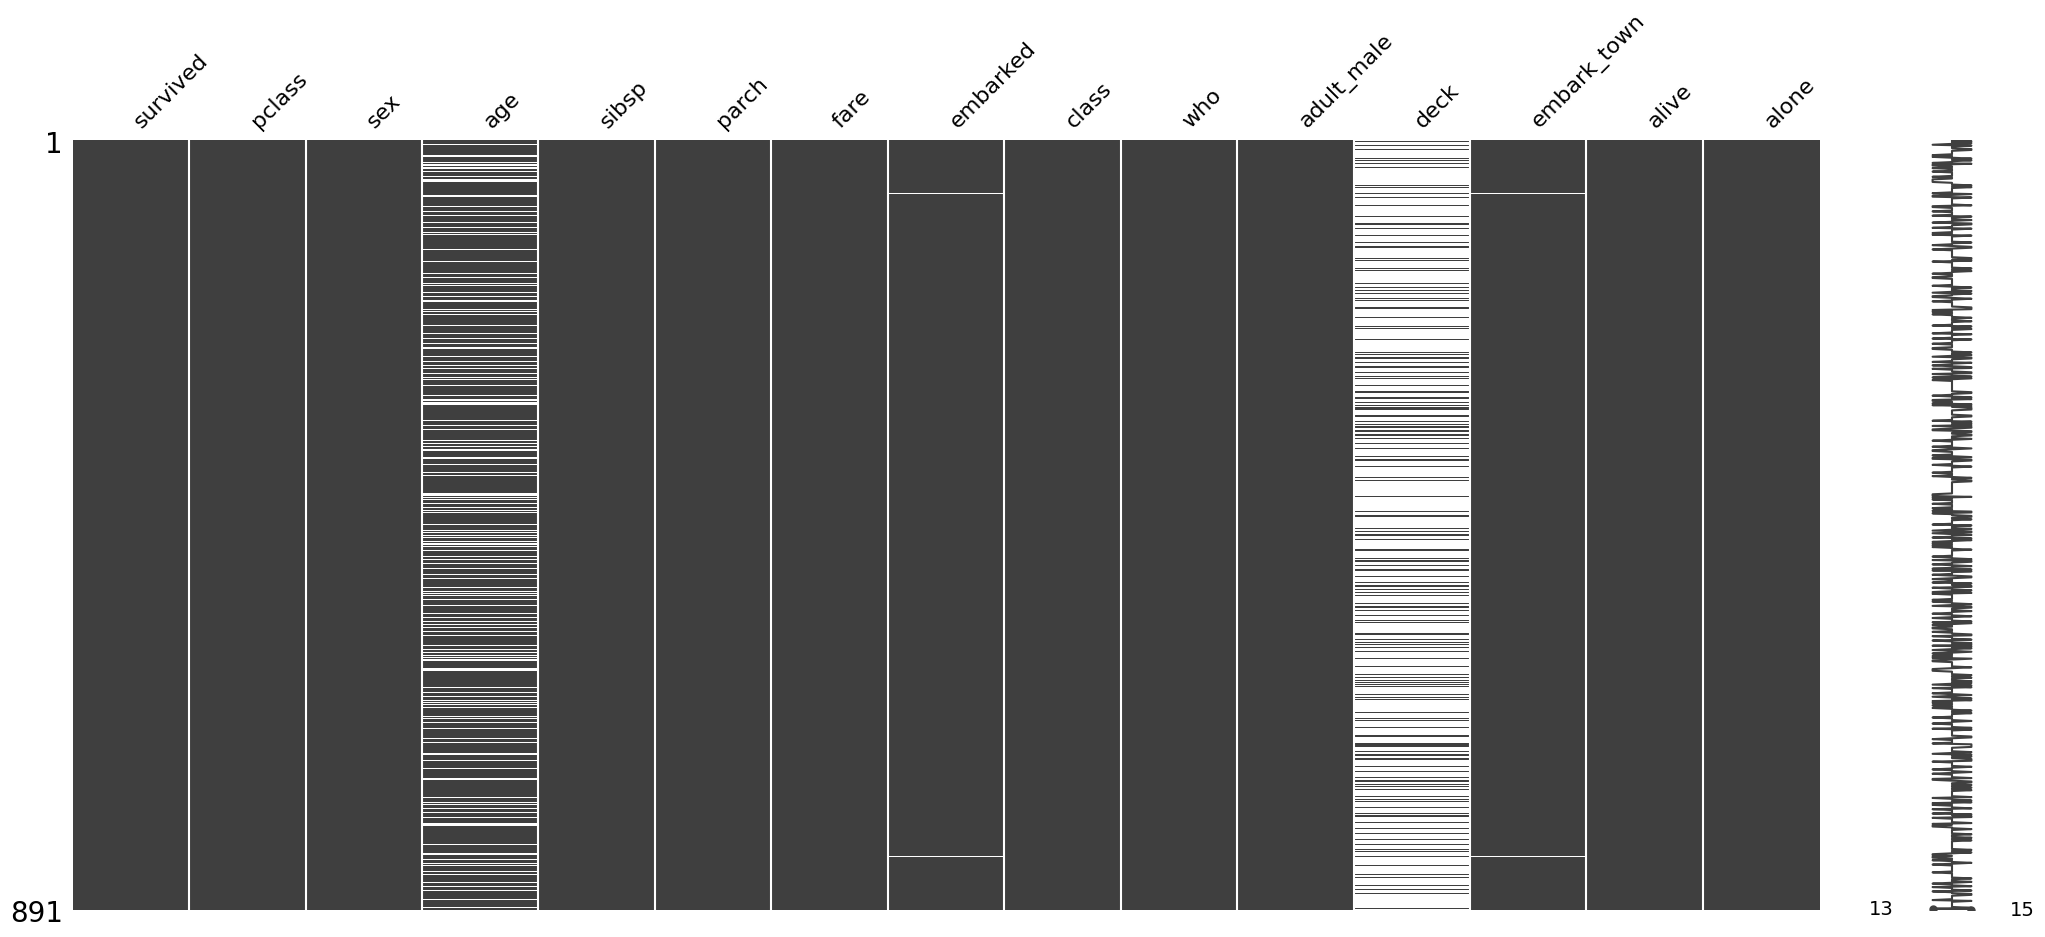

In [29]:
import pandas as pd
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("titanic")
msno.matrix(df)

<Axes: >

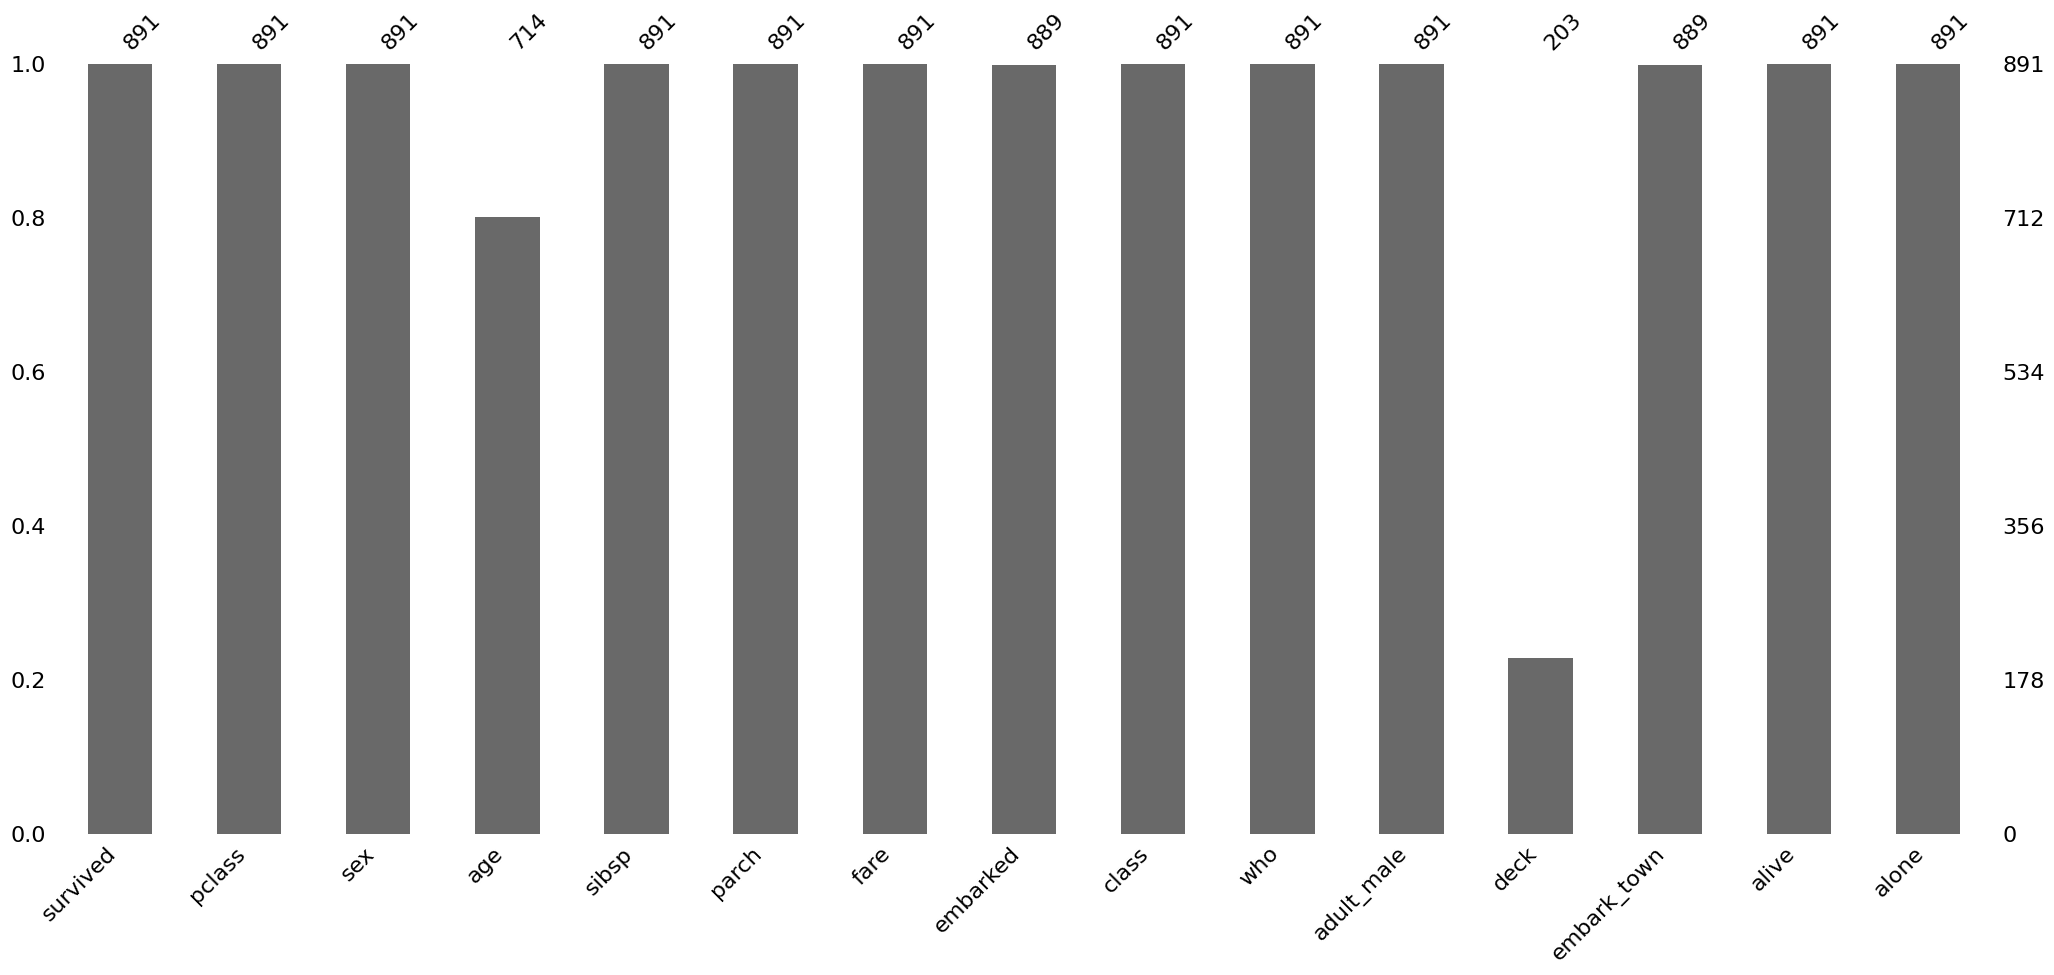

In [30]:
msno.bar(df)

In [31]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [32]:
# Count missing values in each column
 
missing_counts = df.isnull().sum()

# Calculate percentage of missing values

missing_percentages = round(100 * df.isnull().sum() / len(df), 2)

# Combine counts and percentages in a single dataframe
missing_table = pd.concat(
    [missing_counts, missing_percentages],
    axis=1,
    keys=["Missing Count", "Missing Percentage"],
)
missing_table

,Missing Count,Missing Percentage
survived,0,0.00
pclass,0,0.00
sex,0,0.00
age,177,19.87
sibsp,0,0.00
parch,0,0.00
fare,0,0.00
embarked,2,0.22
class,0,0.00
who,0,0.00


Text(0.5, 1.0, 'Matrix Plot of Missing Values')

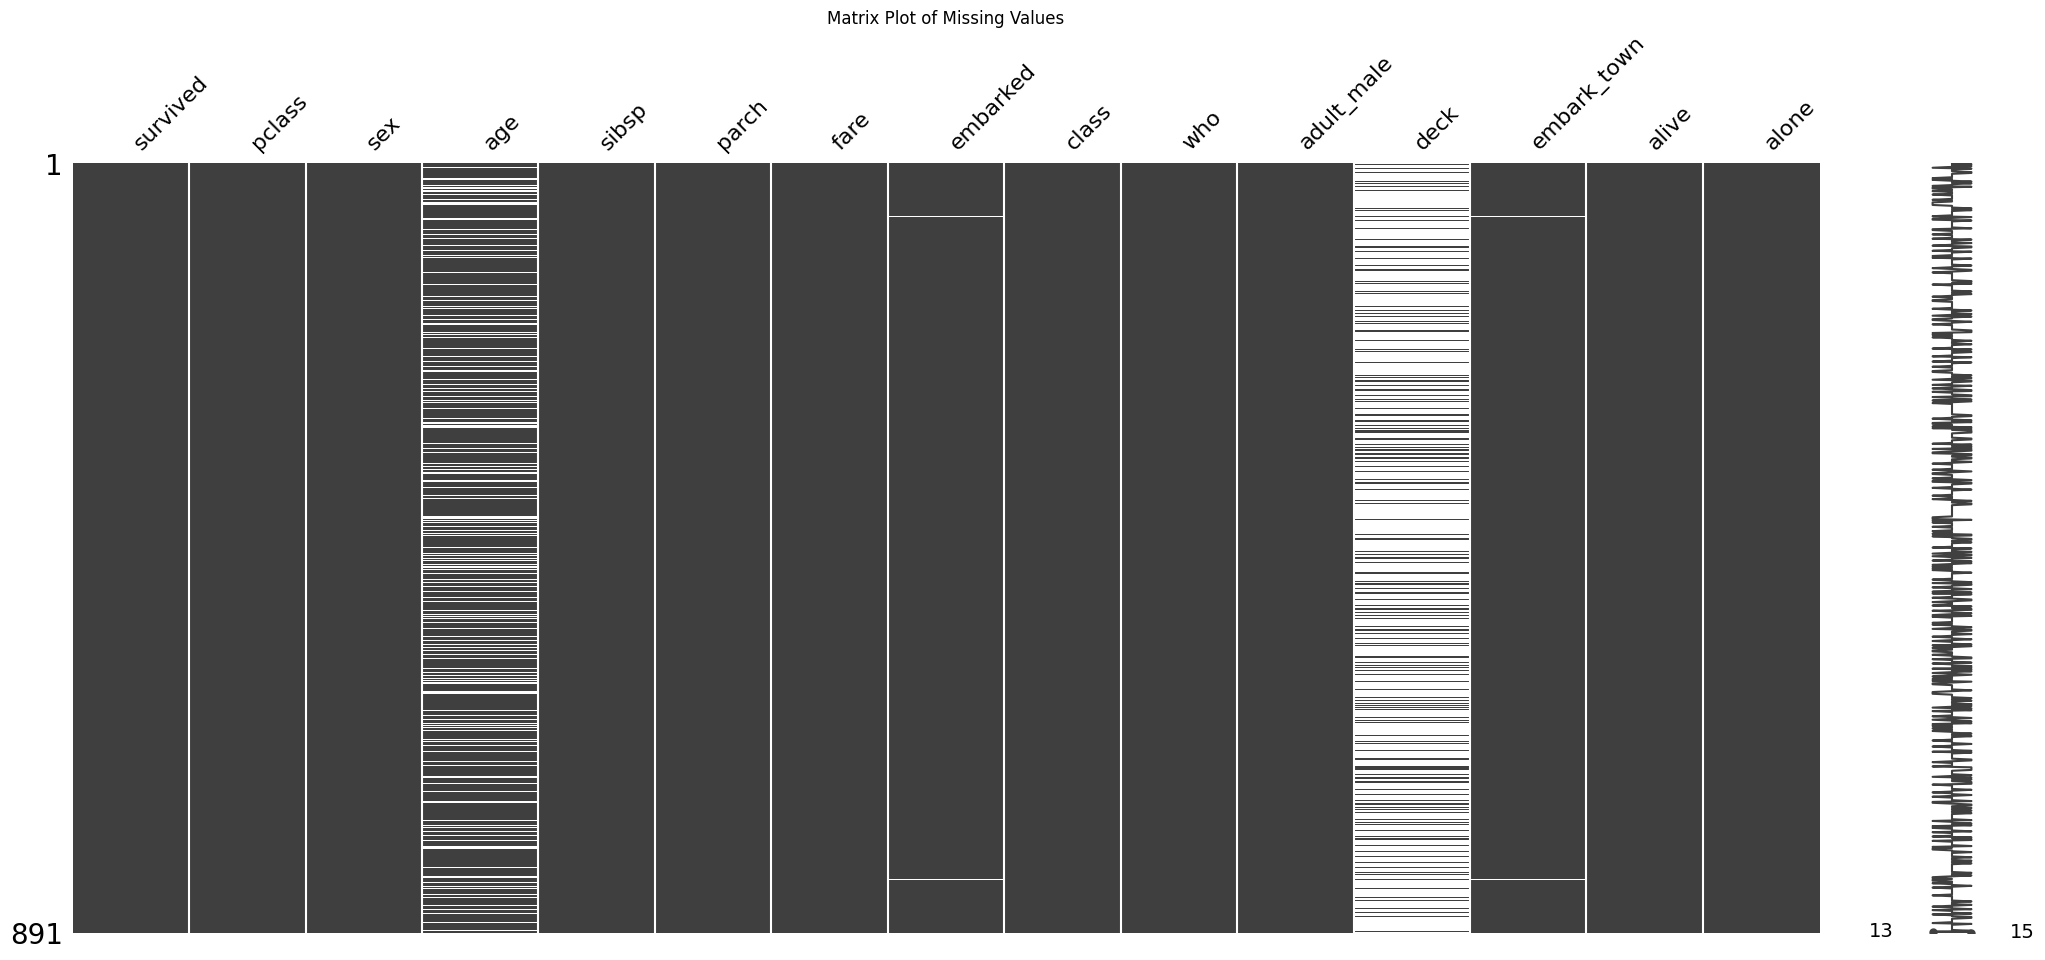

In [33]:
# Matrix plot
msno.matrix(df)
plt.title("Matrix Plot of Missing Values")

In [34]:
df.loc[0, "sex"] = "N/A"


# Check for suspicious values that might represent missing data

suspicious_values = ["N/A", "None", "-999", "", " "]

for column in df.columns:
    if df[column].dtype == "object":  # Only check string columns
        value_counts = df[column].value_counts()
        for value in suspicious_values:
            if value in value_counts.index:
                print(
                    f"Column '{column}' contains {value_counts[value]} instances of '{value}'"
                )

Column 'sex' contains 1 instances of 'N/A'


In [35]:
# Convert suspicious values to NaN

df = df.replace(suspicious_values, np.nan)
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,NaN,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [36]:
# Assessing the Impact of Missing Data

def categorize_missingness(df, threshold=5):
    missing_percentages = 100 * df.isnull().sum() / len(df)

    no_missing = missing_percentages[missing_percentages == 0].index.tolist()
    low_missing = missing_percentages[
        (missing_percentages > 0) & (missing_percentages <= threshold)
    ].index.tolist()
    high_missing = missing_percentages[missing_percentages > threshold].index.tolist()

    print(f"Variables with no missing data: {no_missing}")
    print(f"Variables with low missing data (<= {threshold}%): {low_missing}")
    print(f"Variables with high missing data (> {threshold}%): {high_missing}")


categorize_missingness(df)

Variables with no missing data: ['survived', 'pclass', 'sibsp', 'parch', 'fare', 'class', 'who', 'adult_male', 'alive', 'alone']
Variables with low missing data (<= 5%): ['sex', 'embarked', 'embark_town']
Variables with high missing data (> 5%): ['age', 'deck']


In [37]:
# Imputation Techniques

# Load the Titanic dataset

titanic = sns.load_dataset("titanic")

print(titanic.isnull().sum())

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [38]:
df['age']

0      22.0
1      38.0
2      26.0
3      35.0
4      35.0
       ... 
886    27.0
887    19.0
888     NaN
889    26.0
890    32.0
Name: age, Length: 891, dtype: float64

In [ ]:
# Mean imputation for 'age'

titanic["age_mean_imputed"] = titanic["age"].fillna(titanic["age"].mean())

## mean is efected by outliers

In [47]:
# Median imputation for 'age'

titanic["age_median_imputed"] = titanic["age"].fillna(titanic["age"].median())

## median is not efected alot by outliers

<Axes: >

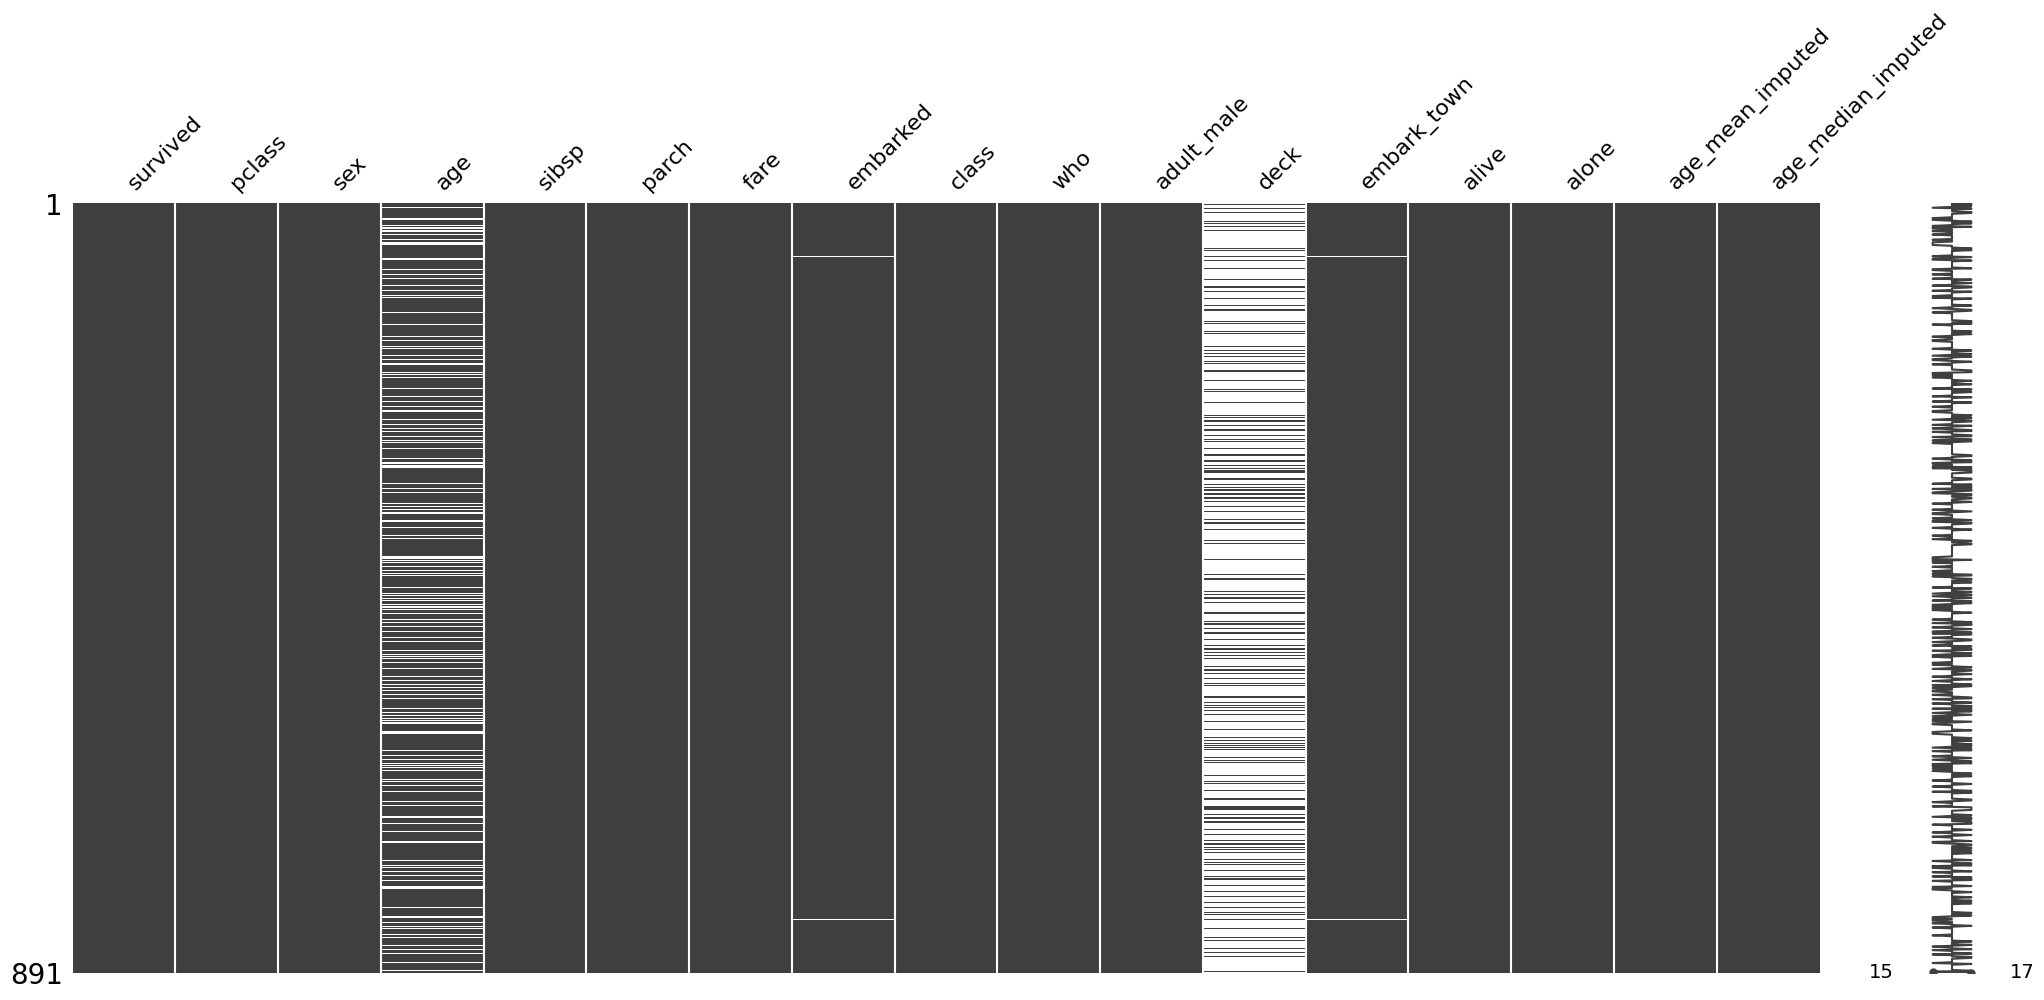

In [46]:
msno.matrix(titanic)

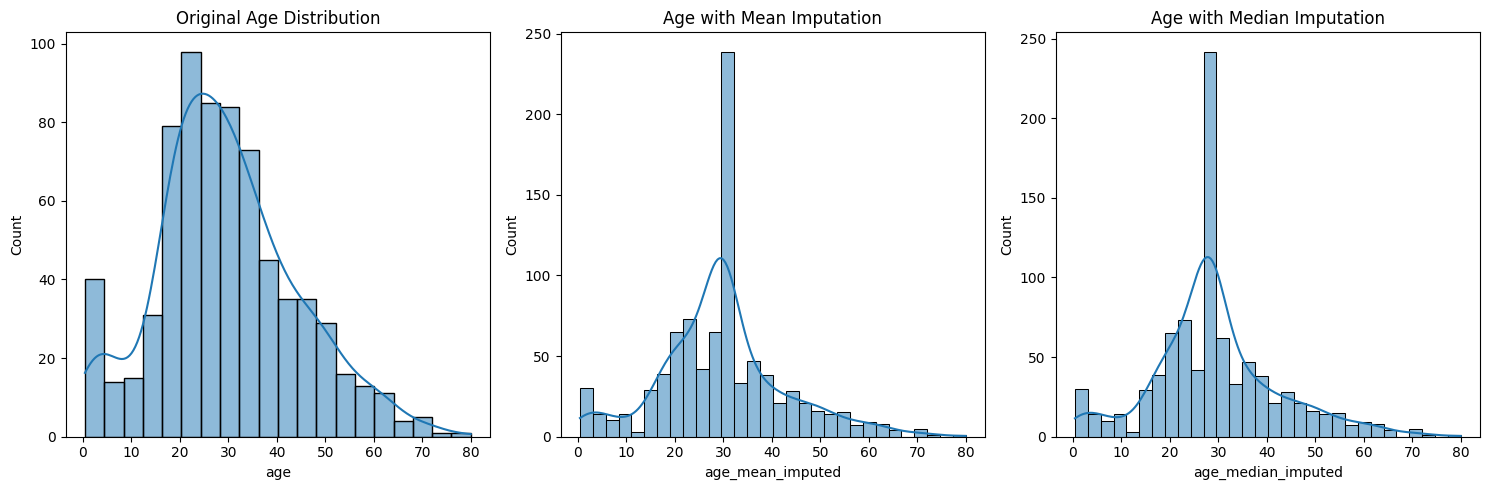

In [42]:
# Visualize the results

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))
sns.histplot(titanic["age"], kde=True, ax=ax1)
ax1.set_title("Original Age Distribution")

sns.histplot(titanic["age_mean_imputed"], kde=True, ax=ax2)
ax2.set_title("Age with Mean Imputation")

sns.histplot(titanic["age_median_imputed"], kde=True, ax=ax3)
ax3.set_title("Age with Median Imputation")

plt.tight_layout()

In [48]:
# Mod imputation for Categorical

titanic["embarked_mode_imputed"] = titanic["embarked"].fillna(
    titanic["embarked"].mode()[0]
)

print("Original 'embarked' value counts:")
print(titanic["embarked"].value_counts(dropna=False))
print("\n'embarked' value counts after mode imputation:")
print(titanic["embarked_mode_imputed"].value_counts(dropna=False))

Original 'embarked' value counts:
embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

'embarked' value counts after mode imputation:
embarked_mode_imputed
S    646
C    168
Q     77
Name: count, dtype: int64


In [49]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LinearRegression

In [50]:
# Select features for imputation

features_for_imputation = ["pclass", "sex", "fare", "age"]
titanic_subset = titanic[features_for_imputation].copy()

In [51]:
# Encode categorical variable

titanic_subset["sex"] = titanic_subset["sex"].map({"male": 0, "female": 1})

In [56]:
imputer = IterativeImputer(estimator=LinearRegression(), random_state=0)
titanic_imputed = pd.DataFrame(
    imputer.fit_transform(titanic_subset), columns=titanic_subset.columns
)
titanic_imputed.head(20)

,pclass,sex,fare,age
0,3.0,0.0,7.2500,22.000000
1,1.0,1.0,71.2833,38.000000
2,3.0,1.0,7.9250,26.000000
3,1.0,1.0,53.1000,35.000000
4,3.0,0.0,8.0500,35.000000
5,3.0,0.0,8.4583,26.057135
6,1.0,0.0,51.8625,54.000000
7,3.0,0.0,21.0750,2.000000
8,3.0,1.0,11.1333,27.000000
9,2.0,1.0,30.0708,14.000000


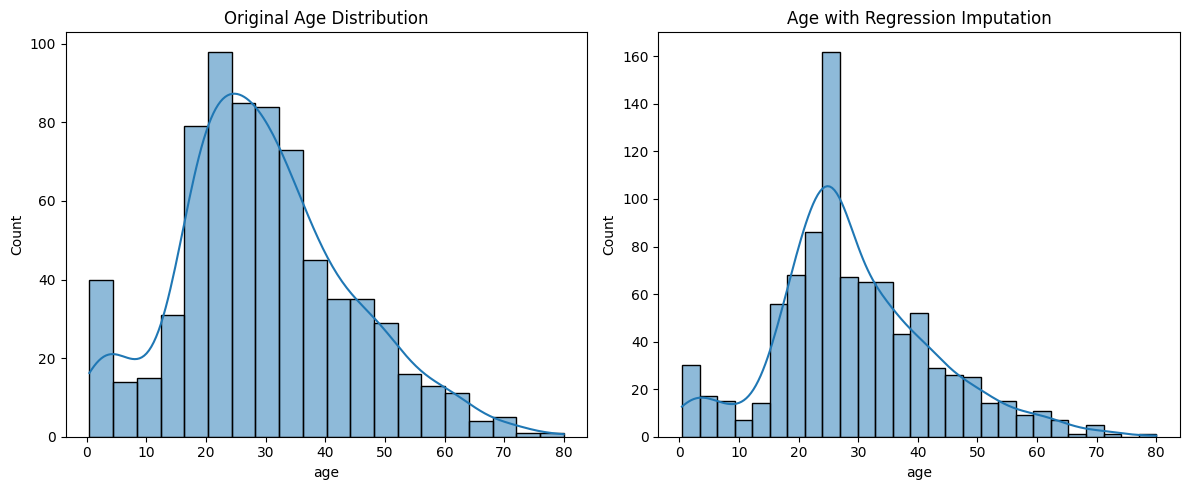

In [53]:
# Visualize original vs imputed age

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(titanic_subset["age"], kde=True, ax=ax1)
ax1.set_title("Original Age Distribution")
sns.histplot(titanic_imputed["age"], kde=True, ax=ax2)
ax2.set_title("Age with Regression Imputation")
plt.tight_layout()
plt.show()

In [60]:
from sklearn.impute import KNNImputer

imputer = KNNImputer(n_neighbors=5)
titanic_knn_imputed = pd.DataFrame(
    imputer.fit_transform(titanic_subset), columns=titanic_subset.columns
)
titanic_knn_imputed 

,pclass,sex,fare,age
0,3.0,0.0,7.2500,22.0
1,1.0,1.0,71.2833,38.0
2,3.0,1.0,7.9250,26.0
3,1.0,1.0,53.1000,35.0
4,3.0,0.0,8.0500,35.0
...,...,...,...,...
886,2.0,0.0,13.0000,27.0
887,1.0,1.0,30.0000,19.0
888,3.0,1.0,23.4500,29.2
889,1.0,0.0,30.0000,26.0


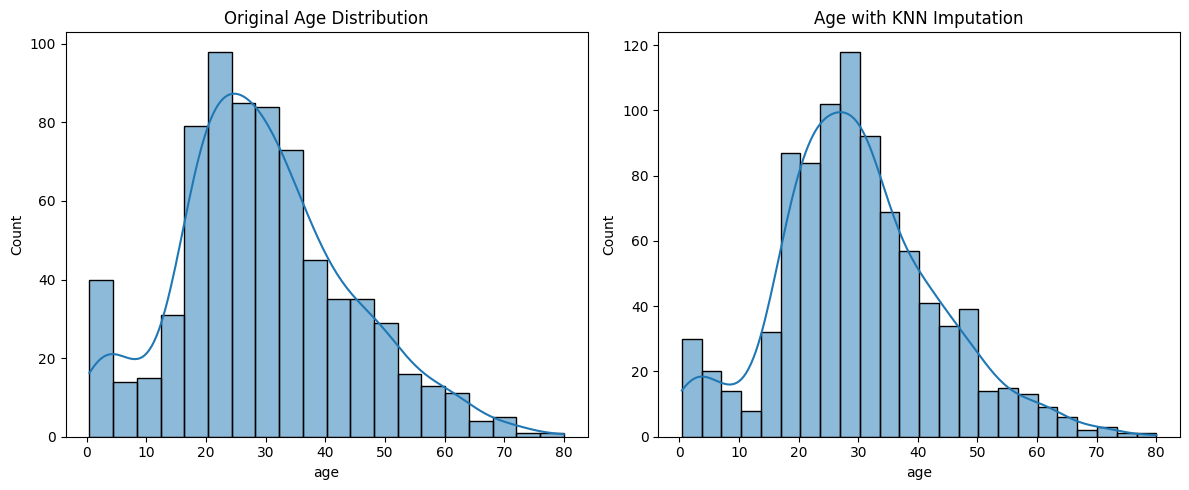

In [59]:
# Visualize KNN imputed age

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(titanic_subset["age"], kde=True, ax=ax1)
ax1.set_title("Original Age Distribution")
sns.histplot(titanic_knn_imputed["age"], kde=True, ax=ax2)
ax2.set_title("Age with KNN Imputation")
plt.tight_layout()
plt.show()

In [61]:
# Load and modify the flights dataset to simulate missing data

taxis = sns.load_dataset("taxis")
taxis.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [62]:
taxis.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [63]:
taxis.loc[2, "pickup"] = np.nan
taxis.loc[3, "pickup"] = np.nan

In [64]:
taxis.head(5)

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,NaT,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,NaT,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [65]:
taxis["pickup"].ffill().head(5)

0   2019-03-23 20:21:09
1   2019-03-04 16:11:55
2   2019-03-04 16:11:55
3   2019-03-04 16:11:55
4   2019-03-30 13:27:42
Name: pickup, dtype: datetime64[ns]

In [66]:
taxis["pickup"].bfill().head(5)

0   2019-03-23 20:21:09
1   2019-03-04 16:11:55
2   2019-03-30 13:27:42
3   2019-03-30 13:27:42
4   2019-03-30 13:27:42
Name: pickup, dtype: datetime64[ns]

In [67]:
taxis["pickup"].interpolate().head(5)

0   2019-03-23 20:21:09.000000000
1   2019-03-04 16:11:55.000000000
2   2019-03-13 07:17:10.666666752
3   2019-03-21 22:22:26.333333248
4   2019-03-30 13:27:42.000000000
Name: pickup, dtype: datetime64[ns]

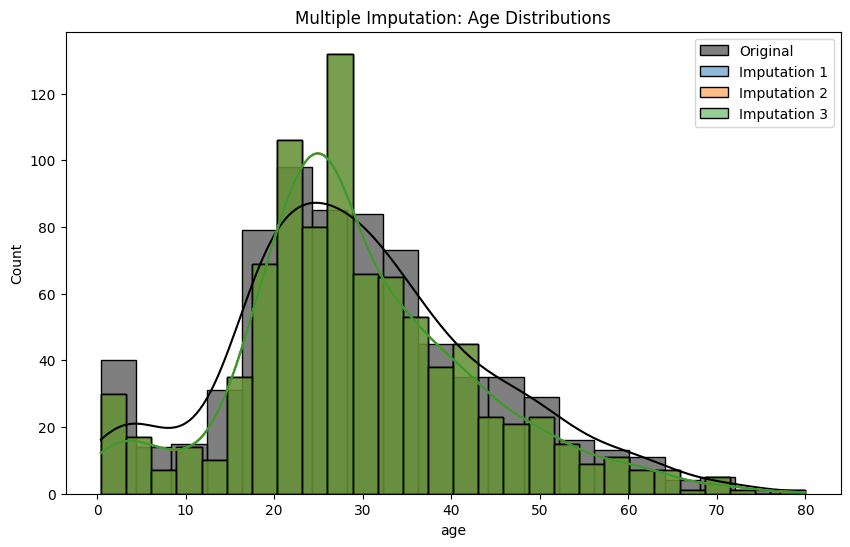

In [68]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

# Create multiple imputed datasets
n_imputations = 3
imputed_datasets = []

for i in range(n_imputations):
    imputer = IterativeImputer(random_state=i)
    imputed_datasets.append(
        pd.DataFrame(
            imputer.fit_transform(titanic_subset), columns=titanic_subset.columns
        )
    )

# Visualize multiple imputations for age
plt.figure(figsize=(10, 6))
sns.histplot(titanic_subset["age"], kde=True, color="black", label="Original")
for i, imputed_df in enumerate(imputed_datasets):
    sns.histplot(imputed_df["age"], kde=True, alpha=0.5, label=f"Imputation {i+1}")
plt.title("Multiple Imputation: Age Distributions")
plt.legend()
plt.show()